In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
from power_estimator.power_estimator import Power_Estimator
import matplotlib.pyplot as plt
from scipy.signal import lfilter

In [2]:
pe = Power_Estimator(alpha=0.0001)

In [3]:
# Generate an AR(1) process with correlation rho, zero mean and variance process_var
samples = 1_000_000
process_var = 1.0
rho = 0.9
noise_var = process_var*(1.0-(rho**2))

rng = np.random.default_rng()

v = rng.normal(loc=0.0, scale=np.sqrt(noise_var), size=samples)

x = lfilter([1],[1, -rho], v)


In [4]:
estimate = np.zeros(samples)
for i in range(samples):
    pe.update(new_sample=x[i])
    estimate[i] = pe.read_estimate()

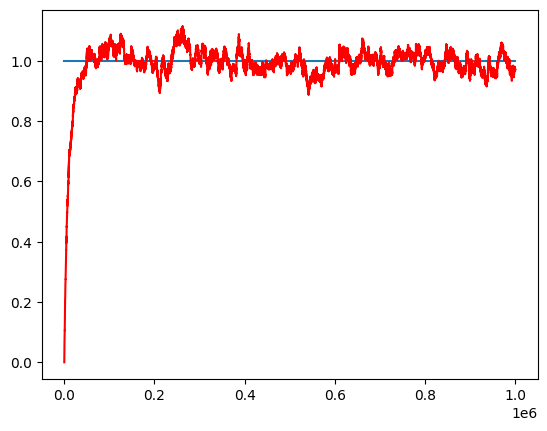

In [5]:
plt.plot([0, samples-1],[process_var,process_var])
plt.plot(estimate,'r')